In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from dataclasses import dataclass

%matplotlib inline

In [5]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'

In [8]:
! /opt/homebrew/bin/wget $data

--2026-10-15 18:07:50--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.108.133, 185.199.109.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  1.37MB/s    in 0.4s    

2026-10-15 18:07:51 (1.37 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



In [9]:
print(data)

https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv


In [14]:
df = pd.read_csv('car_fuel_efficiency_2026.csv')

In [15]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [16]:
columns = ['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg']

In [24]:
short_df = df[columns]
short_df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

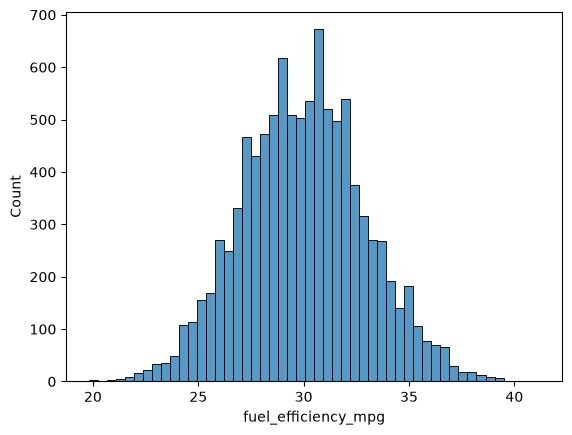

In [25]:
sns.histplot(short_df.fuel_efficiency_mpg, bins=50)

In [26]:
short_df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [28]:
short_df.horsepower.median()

np.float64(254.0)

In [29]:
n = len(short_df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = short_df.iloc[idx[:n_train]]
df_val = short_df.iloc[idx[n_train:n_train + n_val]]
df_test = short_df.iloc[idx[n_train + n_val:]]

In [31]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [32]:
df_val.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
2480,2240,265.0,3990,2004,30.4
289,2390,259.0,4770,2019,32.8
6086,2360,265.0,4320,2018,27.8
3075,2430,279.0,4430,2008,28.6
8123,2220,249.0,4030,1999,31.1


In [33]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [35]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [44]:
X_train_zeros = df_train.fillna(0).values
X_train_mean = df_train.fillna(df_train.horsepower.mean()).values

In [45]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [46]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [47]:
w0, w = train_linear_regression(X_train_zeros, y_train)
y_pred_zeros = w0 + X_train_zeros.dot(w)

w0, w = train_linear_regression(X_train_mean, y_train)
y_pred_mean = w0 + X_train_mean.dot(w)

In [48]:
y_pred_zeros

array([34.07471478, 29.24093577, 32.95179055, ..., 29.32203017,
       31.8448482 , 29.69112172], shape=(6000,))

In [49]:
y_pred_mean

array([33.9590606 , 29.31436861, 32.76131994, ..., 29.30040609,
       31.92376266, 29.67268373], shape=(6000,))

<Axes: ylabel='Count'>

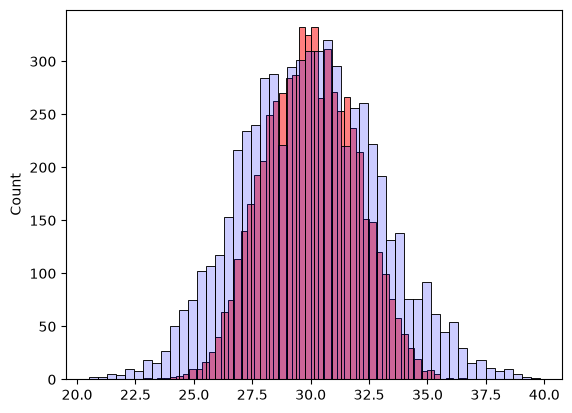

In [56]:
sns.histplot(y_pred_zeros, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.2, bins=50)

<Axes: ylabel='Count'>

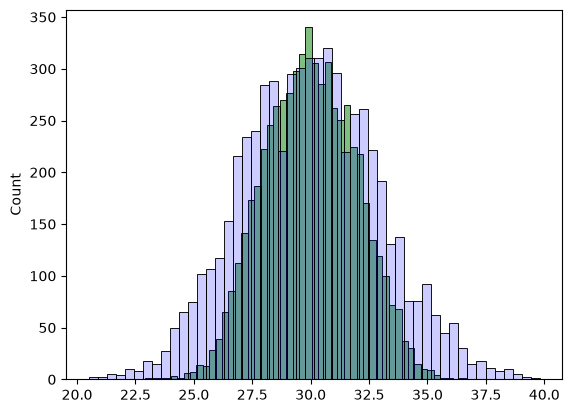

In [55]:
sns.histplot(y_pred_mean, color='green', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.2, bins=50)

In [58]:
round(rmse(y_train, y_pred_zeros), 3)

np.float64(2.2)

In [60]:
round(rmse(y_train, y_pred_mean), 3)

np.float64(2.198)

In [61]:
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [ ]:
@dataclass
class LinearRegressionResult:
    regularizaion: float
    score: float
    seed: float
    standardDeviation: float
    
def prepare_X(df):
df_num = df[base]
df_num = df_num.fillna(0)
X = df_num.values
return X

def train_linear_regression_reg(X, y, regs=[0.001]):
    results: list[LinearRegressionResult]
    for r in regs:
        # X_train = prepare_X(df_train)
        w0, w = train_linear_regression_reg(X_train_zeros, y_train, r=r)

        X_val = df_val.fillna(0).values
        y_pred = w0 + X_val.dot(w)
        score = round(rmse(y_val, y_pred), 3)
        
        results = results + (r, w0, score)
        print(results)
return results
        

0 -153.8849618823488 2.205
0.01 -148.30921244069182 2.206
0.1 -111.8387103928716 2.224
1 -32.331865965012575 2.349
5 -7.772852209986799 2.409
10 -3.987116416021029 2.419
100 -0.4082196488466061 2.429


In [ ]:
# Question 5
def train_linear_regression(X, y, regs, seeds):
    for seed in seeds:
        n = len(short_df)
        n_val = int(n * 0.2)
        n_test = int(n * 0.2)
        n_train = n - n_val - n_test

        np.random.seed(seed)
        idx = np.arange(n)
        np.random.shuffle(idx)

        df_train = short_df.iloc[idx[:n_train]]
        df_val = short_df.iloc[idx[n_train:n_train + n_val]]
        df_test = short_df.iloc[idx[n_train + n_val:]]
        
        y_train = df_train.fuel_efficiency_mpg.values
        y_val = df_val.fuel_efficiency_mpg.values
        y_test = df_test.fuel_efficiency_mpg.values
        
        del df_train['fuel_efficiency_mpg']
        del df_val['fuel_efficiency_mpg']
        del df_test['fuel_efficiency_mpg']
        
        X_train_zeros = df_train.fillna(0).values
        train_linear_regression_reg(X, y, regs)

train_linear_regression(X_train_zeros, y_train, [0], [0, 1, 2, 3, 4, 5, 6, 7, 8, 9])